# Day I - B2) 2D Magnetostatics: Unified Nonlinear Solvers

- **<font color='green'>[RUN & OBSERVE]</font>** $\rightarrow$ run directly
- **<font color='orange'>[RUN & PLAY]</font>** $\rightarrow$ run directly, change parameters
- **<font color='red'>[FILL & RUN]</font>**    $\rightarrow$ fill before running
- **<font color='magenta'>[FILL & PLAY]</font>** $\rightarrow$ fill and change parameters


TODO before on the blackboard: unifying fixed-point, Kačanov and Newton.

_______
## Outlines:

<a id='outlines'></a>

- [**1) Unified framework (eqs 4-5)**](#1_unified_framework)
- [**2) Geometry**](#2_geometry)
- [**3) Material properties**](#3_material_properties)
- [**4) Function space + residual**](#4_fes_residual)
    - [a) FES](#4a_fes)
    - [b) curl operator](#4b_curl)
    - [c) Residual](#4c_residual)
- [**5) Unified iterative solver**](#5_unified_solver)
- [**6) Three linearization operators**](#6_three_lin_ops)
    - [a) Fixed-point (constant chi, damped)](#6a_fixed_point)
    - [b) Kačanov (chord chi)](#6b_kacanov)
    - [c) Newton (full Jacobian)](#6c_newton)
- [**7) Run all three solvers**](#7_run_all_solvers)
- [**8) Convergence comparison**](#8_convergence_comparison)
- [**9) Post-processing: flux density**](#9_post_processing)
- [**10) Notes**](#10_notes)

|**<u>Objective</u>** : Implement and compare fixed-point, Kačanov and Newton nonlinear solvers|
|---|
|*Indicative duration* : 1 hour|

<a id='1_unified_framework'></a>
_______
## 1) Unified framework (eqs 4-5)

We want to find $a \in H^1_0(\Omega)$ such that the residual vanishes:

$$ R(a; v) = \int_\Omega \nu(|\text{curl}\,a|^2)\,\text{curl}\,v\cdot\text{curl}\,a \;-\; \int_\Omega v\,j \;=\; 0 \qquad \forall v\in H^1_0(\Omega) $$

Starting from an initial guess $a^0$, we construct a sequence $a^n$ via the **update formula** (eq. 4 of the reference):

$$ a^{n+1} = a^n + \tau^n\,\delta a^n, \qquad n \geq 0 $$

where $\delta a^n$ is the **search direction**, defined by solving the linear variational problem (eq. 5 of the reference):

$$ \langle \nu^n\,\text{curl}\,\delta a^n,\; \text{curl}\,v\rangle_\Omega \;=\; -R(a^n; v) \qquad \forall v\in H^1_0(\Omega) $$

The RHS $-R(a^n; v)$ expands to:
$$ -R(a^n; v) = \int_\Omega v\,j \;-\; \int_\Omega \nu(|\text{curl}\,a^n|^2)\,\text{curl}\,v\cdot\text{curl}\,a^n $$

This is the standard current-density source. In the reference document the RHS is written as $\langle h_s, \text{curl}\,v\rangle$ (magnetizing-field source). The two are **equivalent in 2D** for $v\in H^1_0$ via integration by parts.

The three solvers differ **only** in the choice of the generalized reluctivity $\nu^n$:

| Solver | Choice of $\nu^n$ | Matrix | Factorization |
|---|---|---|---|
| **Fixed-point** | $\nu^n = \bar\nu > 0$ (constant, damped by $\omega$) | **Same** every step | **Once** before loop |
| **Kačanov** | $\nu^n = \nu(|\text{curl}\,a^n|^2)$ (chord, frozen at $a^n$) | Changes each step | Each iteration |
| **Newton** | $\nu^n = \partial_b^2 w(\text{curl}\,a^n)$ (Jacobian) | Changes each step | Each iteration |

In 2D, we enforce the curl operator:
$$ \text{curl}(\cdot) \;=\; \begin{pmatrix} 0 & 1 \\ -1 & 0 \end{pmatrix} \text{grad}(\cdot) $$

<a id='2_geometry'></a>
_______
## 2) Geometry

Closed iron core with winding, no airgap (risk of saturation!).

|**<font color='green'>[RUN & OBSERVE]</font>**|
|---|

In [1]:
from utils.myGeometries import gaped_inductor
from ngsolve.webgui import Draw
mesh = gaped_inductor(airgap = 0, h = 0.01)  # no airgap
Draw(mesh.MaterialCF({"condN":1, "iron":2, "condP":3}), mesh)

WebGLScene

|**<font color='green'>[RUN & OBSERVE]</font>**|
|---|

In [2]:
print(f"Regions : {mesh.GetMaterials()}")
print(f"Boundaries : {mesh.GetBoundaries()}")

Regions : ('air', 'iron', 'condP', 'condN')
Boundaries : ('out', 'out', 'out', 'out', '', '', '', '', '', '', '', '', '', '', '', '', '', '', '', '')


<a id='3_material_properties'></a>
_______
## 3) Material properties

The magnetic reluctivity in iron depends on $b^2 = |\text{curl}\,a|^2$:

$$ \nu_{\text{iron}}(b^2) = 100 + 10\exp(1.8\,b^2) $$

Its derivative w.r.t. $b^2$:

$$ \frac{d\nu}{db^2}(b^2) = 18\exp(1.8\,b^2) $$

|**<font color='green'>[RUN & OBSERVE]</font>**|
|---|

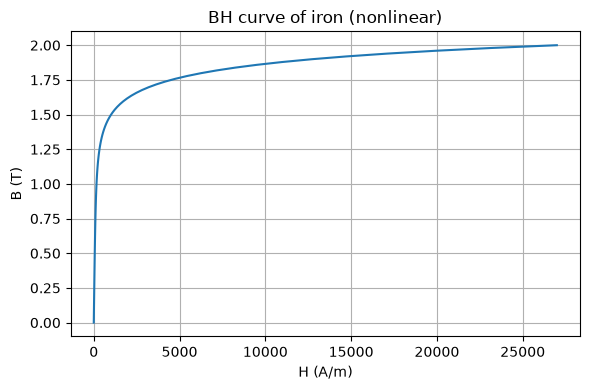

In [3]:
from numpy import pi
from ngsolve import exp
import numpy as np
import matplotlib.pyplot as plt

mu0 = 4e-7 * pi      # H/m, void magnetic permeability
J = 10e6              # A/m^2, current density

def nu_iron(b2):
    """Magnetic reluctivity of iron w.r.t. b²"""
    return 100 + 10 * exp(1.8 * b2)

def dnu_iron_db2(b2):
    """Derivative of reluctivity w.r.t. b²"""
    return 18 * exp(1.8 * b2)

# Plot BH curve
b = np.linspace(0, 2, 100)
H_vals = nu_iron(b**2) * b   # H = nu(B²)*B  (scalar field)
plt.figure(figsize=(6, 4))
plt.plot(H_vals, b)
plt.xlabel("H (A/m)"); plt.ylabel("B (T)")
plt.title("BH curve of iron (nonlinear)")
plt.grid(True); plt.tight_layout()
plt.show()

<a id='4_fes_residual'></a>
_______
## 4) Function space + residual

<a id='4a_fes'></a>
### a) Function space

|**<font color='red'>[FILL & RUN]</font>**|
|---|

In [4]:
from ngsolve import H1
fes = H1(mesh, order = 1, dirichlet = "out")

<a id='4b_curl'></a>
### b) curl operator

In 2D, curl acts on a scalar as:
$$ \text{curl}(u) = \begin{pmatrix} 0 & 1 \\ -1 & 0 \end{pmatrix} \text{grad}(u) $$

|**<font color='green'>[RUN & OBSERVE]</font>**|
|---|

In [5]:
from ngsolve import grad, dx, LinearForm, BilinearForm, CoefficientFunction, GridFunction
R = CoefficientFunction(((0, 1), (-1, 0)), dims = (2, 2))  # -pi/2 rotation
curl = lambda u: R * grad(u)

<a id='4c_residual'></a>
### c) Residual functional

The residual $R(a; v)$ reads:

$$ R(a; v) = \int_\Omega \nu(|\text{curl}\,a|^2)\,\text{curl}\,v\cdot\text{curl}\,a - \int_\Omega v\,j $$

|**<font color='red'>[FILL & RUN]</font>**|
|---|

In [6]:
a, v = fes.TnT()

def residual(a, v):
    """Nonlinear residual functional.
    
    Returns a symbolic CoefficientFunction expression.
    Must be wrapped in LinearForm(...).Assemble().vec to get the discrete vector.
    """
    b2 = curl(a)**2  # |curl(a)|^2 (scalar)
    res = curl(v) * (1/mu0) * curl(a) * dx("air|condP|condN")
    res += curl(v) * nu_iron(b2) * curl(a) * dx("iron")
    res += -v * J * dx("condP") + v * J * dx("condN")
    return res

<a id='5_unified_solver'></a>
_______
## 5) Unified iterative solver

Based on eqs (4)-(5) of the reference. At each iteration $n$:
1. Compute residual vector $\mathbf{r} = R(a^n, \phi_i)$
2. Solve $K(\nu^n)\,\mathbf{d} = \mathbf{r}$
3. Update: $\mathbf{a}^{n+1} = \mathbf{a}^n - \tau^n \mathbf{d}$ (since $\delta a = -\mathbf{d}$)
4. Backtracking: halve $\tau$ if residual does not decrease

|**<font color='red'>[FILL & RUN]</font>**|
|---|

In [7]:
from time import perf_counter

def iterative_solve(fes, residual, lin_op, step_init=0.01, tol=1e-8, maxit=500,
                    optimize=False, constant_step=None, name="", verbosity=1):
    """Unified iterative solver based on eqs (4)-(5) from the reference.

    constant_step: if a float, use a FIXED relaxation tau^n = constant_step
        (damped iteration, no backtracking growth) -- used for the fixed-point.
        If None, use adaptive backtracking (step grows up to 1.0) -- used for
        Kačanov and Newton.
    """
    da, v = fes.TnT()
    sol = GridFunction(fes)
    resList = []
    step = constant_step if constant_step is not None else step_init
    t_start = perf_counter()
    free_dofs = fes.FreeDofs()
    
    for i in range(maxit):
        res = LinearForm(residual(sol, v)).Assemble().vec
        norm_r = np.linalg.norm(res.FV().NumPy()[free_dofs])
        resList.append(norm_r)
        if verbosity >= 2:
            print(f"  {name:12s} iter {i:3d}: ||R|| = {norm_r:.5e} | step = {step:.2e}")
        
        if optimize:
            if i == 0:
                K = BilinearForm(lin_op(da, v, sol)).Assemble().mat
                Kinv = K.Inverse(freedofs=free_dofs)
            d = Kinv * res
        else:
            K = BilinearForm(lin_op(da, v, sol)).Assemble().mat
            Kinv = K.Inverse(freedofs=free_dofs)
            d = Kinv * res
        
        sol.vec.data -= step * d
        if constant_step is not None:
            step = constant_step          # fixed relaxation (damped fixed-point)
        elif i > 0 and resList[-1] < resList[-2]:
            step = min(1.0, 1.2 * step)
        else:
            step = step / 2
        if norm_r < tol:
            break
    
    t_end = perf_counter()
    if verbosity >= 1:
        converged = "\u2705" if norm_r < tol else "\u274c"
        print(f"  {converged} {name:12s}: {len(resList)} iters, "
              f"final ||R|| = {resList[-1]:.5e}, "
              f"time = {(t_end - t_start) * 1000:.1f} ms")
    return sol, resList, (t_end - t_start)

<a id='6_three_lin_ops'></a>
_______
## 6) Three linearization operators

Each `lin_op(da, v, aOld)` returns the symbolic bilinear form for the LHS of eq. (5):
$$ \int_\Omega \nu^n\,\text{curl}\,\delta a \cdot \text{curl}\,v $$

|**<font color='red'>[FILL & RUN]</font>**|
|---|

<a id='6a_fixed_point'></a>
### a) Fixed-point: $\nu^n = \bar\nu$ (constant, damped)

The matrix is **iterate-independent**, so we factorize it **once** before the loop
(`optimize=True`); each iteration is then just a cheap sparse solve.

Because $\bar\nu$ is constant, this is a **damped Richardson** iteration:
$$ a^{n+1} = a^n + \omega\,\delta a^n, \qquad \bar\nu\int \text{curl}(\delta a)\cdot\text{curl}(v) = -R(a^n;v) $$
It converges **linearly but slowly**, and only for a relaxation $\omega$ below a
stability threshold. For this strongly nonlinear material we use $\bar\nu=10000$,
$\omega=0.10$ (larger $\omega$ diverges).

|**<font color='orange'>[RUN & PLAY]</font>** — change `bar_nu_iron` and `fp_relax`.

|**<font color='green'>[RUN & PLAY]</font>**|
|---|

In [ ]:
# FIXED-POINT: nu^n = bar_nu (constant, iterate-independent)
bar_nu_iron = 10000.0   # constant reluctivity in iron (hyperparameter)
fp_relax = 0.1         # fixed relaxation (damping); must stay below stability limit

def lin_op_fixed_point(da, v, aOld):
    """Constant chi = bar_nu. Matrix is the same every iteration."""
    b_da_v = curl(da) * curl(v)
    bf = b_da_v * (1/mu0) * dx("air|condP|condN")
    bf += b_da_v * bar_nu_iron * dx("iron")
    return bf

<a id='6b_kacanov'></a>
### b) Kačanov: $\nu^n = \nu(|\text{curl}\,a^n|^2)$ (chord reluctivity)

This is the classic **"frozen coefficient"** (or Picard) iteration.

Algebraic equivalence with the model file's approach:
```
Model file:  K(a_old) * a_new = F       -->  a_new = K(a_old)^{-1} * F
Eq. (5):     K(a_old) * delta_a = F - K(a_old)*a_old  -->  delta_a = K(a_old)^{-1}*F - a_old
             a_new = a_old + delta_a = K(a_old)^{-1} * F   (same result!)
```

|**<font color='green'>[RUN & OBSERVE]</font>**|
|---|

In [ ]:
def lin_op_kacanov(da, v, aOld):
    """Chord reluctivity: nu(|curl(aOld)|^2). Matrix changes each iteration."""
    b2 = curl(aOld)**2
    b_da_v = curl(da) * curl(v)
    bf = b_da_v * (1/mu0) * dx("air|condP|condN")
    bf += b_da_v * nu_iron(b2) * dx("iron")
    return bf

<a id='6c_newton'></a>
### c) Newton: $\nu^n = \partial_b^2 w(\text{curl}\,a^n)$ (full Jacobian)

This is the **full tangent** operator. Matches `d_residual` in the model file.

$$ \int_\Omega \Big[ \nu(b^2)\,\text{curl}\,\delta a\cdot\text{curl}\,v
  \;+\; 2\,\frac{d\nu}{db^2}(b^2)\,(\text{curl}\,a\cdot\text{curl}\,\delta a)\,
  (\text{curl}\,a\cdot\text{curl}\,v) \Big] $$

|**<font color='green'>[RUN & OBSERVE]</font>**|
|---|

In [10]:
def lin_op_newton(da, v, aOld):
    """Full Newton Jacobian. Quadratic convergence; matrix changes each iter."""
    b2 = curl(aOld)**2
    b_da_v = curl(da) * curl(v)
    b_a_v = curl(aOld) * curl(v)
    b_a_da = curl(aOld) * curl(da)
    bf = b_da_v * (1/mu0) * dx("air|condP|condN")
    bf += b_da_v * nu_iron(b2) * dx("iron")
    bf += 2 * b_a_v * b_a_da * dnu_iron_db2(b2) * dx("iron")
    return bf

<a id='7_run_all_solvers'></a>
_______
## 7) Run all three solvers

|**<font color='magenta'>[FILL & PLAY]</font>** — change `solver_choice` to run individual
  solvers, or `"all"` to run all three and compare.

|**<font color='magenta'>[FILL & PLAY]</font>**|
|---|

In [20]:
solver_choice = "all"  # options: "fixed_point", "kacanov", "newton", "all"

solutions = {}
residuals = {}
times = {}

if solver_choice in ("fixed_point", "all"):
    print("\n--- Fixed-point (constant chi, damped, factorized ONCE) ---")
    sol_fp, res_fp, t_fp = iterative_solve(
        fes, residual, lin_op_fixed_point,
        optimize=True, constant_step=fp_relax,
        name="fixed_point", verbosity=2)
    solutions["fixed_point"] = sol_fp
    residuals["fixed_point"] = res_fp
    times["fixed_point"] = t_fp

if solver_choice in ("kacanov", "all"):
    print("\n--- Kačanov (chord reluctivity, re-factor each iter) ---")
    sol_kc, res_kc, t_kc = iterative_solve(
        fes, residual, lin_op_kacanov,
        optimize=False, name="kacanov", verbosity=2)
    solutions["kacanov"] = sol_kc
    residuals["kacanov"] = res_kc
    times["kacanov"] = t_kc

if solver_choice in ("newton", "all"):
    print("\n--- Newton (full Jacobian, re-factor each iter) ---")
    sol_nt, res_nt, t_nt = iterative_solve(
        fes, residual, lin_op_newton,
        optimize=False, name="newton", verbosity=2)
    solutions["newton"] = sol_nt
    residuals["newton"] = res_nt
    times["newton"] = t_nt


--- Fixed-point (constant chi, damped, factorized ONCE) ---
  fixed_point  iter   0: ||R|| = 1.46788e+02 | step = 1.00e+00
  fixed_point  iter   1: ||R|| = 9.60024e+01 | step = 1.00e+00
  fixed_point  iter   2: ||R|| = 8.95756e+07 | step = 1.00e+00
  fixed_point  iter   3: ||R|| = nan | step = 1.00e+00
  fixed_point  iter   4: ||R|| = nan | step = 1.00e+00
  fixed_point  iter   5: ||R|| = nan | step = 1.00e+00
  fixed_point  iter   6: ||R|| = nan | step = 1.00e+00
  fixed_point  iter   7: ||R|| = nan | step = 1.00e+00
  fixed_point  iter   8: ||R|| = nan | step = 1.00e+00
  fixed_point  iter   9: ||R|| = nan | step = 1.00e+00
  fixed_point  iter  10: ||R|| = nan | step = 1.00e+00
  fixed_point  iter  11: ||R|| = nan | step = 1.00e+00
  fixed_point  iter  12: ||R|| = nan | step = 1.00e+00
  fixed_point  iter  13: ||R|| = nan | step = 1.00e+00
  fixed_point  iter  14: ||R|| = nan | step = 1.00e+00
  fixed_point  iter  15: ||R|| = nan | step = 1.00e+00
  fixed_point  iter  16: ||R|| = na

<a id='8_convergence_comparison'></a>
_______
## 8) Convergence comparison

|**<font color='green'>[RUN & OBSERVE]</font>**|
|---|

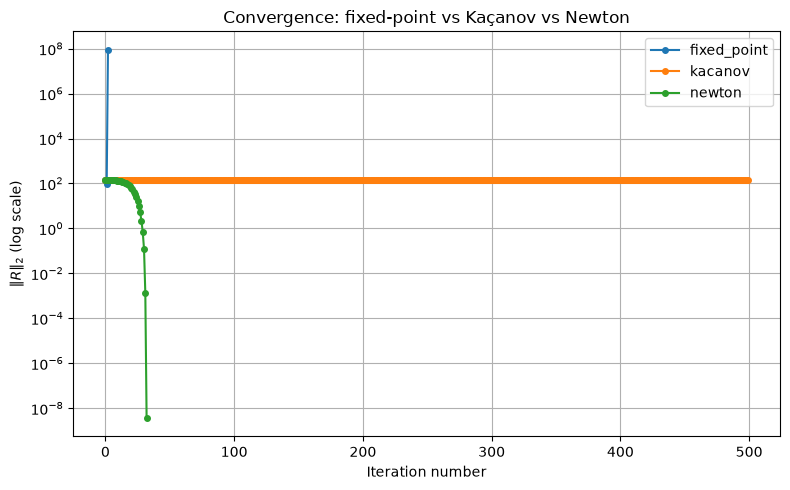

In [21]:
plt.figure(figsize=(8, 5))
for key in residuals:
    plt.semilogy(residuals[key], marker='o', markersize=4, linewidth=1.5, label=key)
plt.xlabel("Iteration number"); plt.ylabel(r"$\|R\|_2$ (log scale)")
plt.title("Convergence: fixed-point vs Ka\u00e7anov vs Newton")
plt.grid(True, which="both"); plt.legend()
plt.tight_layout()
plt.show()

**Expected behavior:**
- **Fixed-point**: many iterations, **slow linear** convergence (it may not reach the
  tolerance within `maxit`). But each iteration is **cheap** because the matrix is
  factorized only **once** — the wall time per iteration is the lowest of the three.
  If you push `fp_relax` up toward the stability limit it converges faster, but past it
  the iteration diverges (try `fp_relax = 0.2` and watch `||R||` blow up).
- **Kačanov**: linear convergence, needs moderate iterations. Each iteration requires reassembly + refactorization.
- **Newton**: very few iterations (often < 5), **quadratic** convergence. Each iteration is expensive, but total time is often best.

|**<font color='green'>[RUN & OBSERVE]</font>**|
|---|

In [13]:
print("\n=== Wall-time comparison ===")
for key in solutions:
    niter = len(residuals[key])
    wall = times[key] * 1000
    print(f"  {key:12s}: {niter:3d} iters, {wall:8.1f} ms")


=== Wall-time comparison ===
  fixed_point : 500 iters,   2067.0 ms
  kacanov     : 500 iters,   5663.7 ms
  newton      :  33 iters,    581.0 ms


<a id='9_post_processing'></a>
_______
## 9) Post-processing: flux density

Compute and visualize the flux density $B = \text{curl}\,a$ for each solver.

|**<font color='red'>[FILL & RUN]</font>**|
|---|

In [ ]:
for key in solutions:
    sol = solutions[key]
    B = curl(sol)
    Draw(B, mesh,
         vectors={"grid_size": 50, "offset": 0.5},
         settings={"Objects": {"Wireframe": False, "Surface": False}})

<a id='10_notes'></a>
_______
## 10) Notes

- This file implements the unified framework from the reference (eqs 3-5).
  The three solvers differ **only** in the choice of $\nu^n$ (generalized reluctivity).
- The **fixed-point** solver uses a **constant** $\bar\nu$, so the LHS matrix is
  iterate-independent: it is factorized **once** (`optimize=True`), making each
  iteration a cheap sparse solve. It converges only as a **damped** iteration
  (fixed relaxation `fp_relax`); without damping the step grows and the
  `exp(1.8\,b^2)` term overflows.
- The **Kačanov** solver uses the chord reluctivity $\nu(|\text{curl}\,a^n|^2)$,
  which is the nonlinear reluctivity frozen at the current iterate. The matrix
  must be reassembled and refactorized at each iteration.
- The **Newton** solver uses the full tangent operator (Jacobian of the residual).
  It achieves **quadratic convergence** near the solution, typically only
  2-5 iterations needed. Each iteration requires reassembly + refactorization.
- For even more robust nonlinear solving (Armijo linesearch, symbolic
  autodiff via `AssembleLinearization`), see `utils/mySolvers.solveNL`.

|**<font color='green'>[RUN & OBSERVE]</font>**|
|---|